# 3. Experimento 1 – Comparação de classificadores

**Projeto:** Agente Identificador de Fraudes Bancárias  
**Disciplina:** Inteligência Artificial – 7º semestre – Ciência da Computação  
**Instituição:** Universidade Presbiteriana Mackenzie – Faculdade de Computação e Informática  
**Professor:** Prof. Dr. Ivan Carlos Alcântara de Oliveira

| Integrante | RA | E-mail |
|---|---|---|
| Cheuk Ki Yu | 10419664 | cheuk.yu@mackenzista.com.br |
| Gabriela Nellessen de Sousa | 10441930 | gabrielanellessen@gmail.com |
| Milton Almeida Leoncio | 10416764 | milton.almeida@live.com |

**Síntese:** Regras estáticas, Regressão Logística, Random Forest, XGBoost, LightGBM, MLP e SVM nas duas bases; efeito do perfil estático na Base A; IC 95% por bootstrap.

**Histórico de alterações**

| Data | Autor | Descrição |
|---|---|---|
| 2026-10-28 | Milton Almeida Leoncio | Versão inicial da etapa nos resultados preliminares (N1) |
| 2026-11-20 | Milton Almeida Leoncio | Versão final do projeto (N2) |

In [1]:
# ========================================================================================
# Projeto: Agente Identificador de Fraudes Bancárias
# Disciplina: Inteligência Artificial - 7º semestre - Ciência da Computação
# Universidade Presbiteriana Mackenzie - Faculdade de Computação e Informática (FCI)
# Professor: Prof. Dr. Ivan Carlos Alcântara de Oliveira
# Integrantes:
#   Cheuk Ki Yu                  - RA 10419664 - cheuk.yu@mackenzista.com.br
#   Gabriela Nellessen de Sousa  - RA 10441930 - gabrielanellessen@gmail.com
#   Milton Almeida Leoncio       - RA 10416764 - milton.almeida@live.com
# Arquivo: notebooks/03_comparacao_modelos.ipynb
# Síntese: Regras estáticas, Regressão Logística, Random Forest, XGBoost, LightGBM, MLP e SVM nas duas bases; efeito do perfil estático na Base A; IC 95% por bootstrap.
# Histórico de alterações:
#   2026-10-28 - Milton Almeida Leoncio - Versão inicial da etapa nos resultados preliminares (N1)
#   2026-11-20 - Milton Almeida Leoncio - Versão final do projeto (N2)
# ========================================================================================

import os, sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
os.environ.setdefault('FRAUDES_ATRIBUTOS', str(RAIZ / 'atributos'))  # saída de preparar_bases.py
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
FIG = RAIZ / 'resultados'

Todos os modelos usam a mesma divisão temporal. O limiar de decisão é o que maximiza o F1 na validação, e as métricas são medidas no teste. Os intervalos de confiança (IC 95%) vêm de bootstrap pareado.

In [2]:
import exp1_modelos as e1
cols = ['conjunto', 'modelo', 'val_pr_auc', 'precision', 'recall', 'f1', 'f1_ic_inf', 'f1_ic_sup', 'pr_auc', 'roc_auc', 'tempo_s']
metB, _ = e1.executar('B')
metB[cols]

,conjunto,modelo,val_pr_auc,precision,recall,f1,f1_ic_inf,f1_ic_sup,pr_auc,roc_auc,tempo_s
0,completo,Regras,0.396,0.328,0.474,0.388,0.327,0.444,0.284,0.912,0.000
1,completo,Regressão Logística,0.287,0.242,0.550,0.336,0.280,0.388,0.213,0.948,1.000
2,completo,Random Forest,0.919,0.750,0.789,0.769,0.715,0.816,0.844,0.984,6.400
3,completo,XGBoost,0.944,0.944,0.784,0.856,0.814,0.899,0.907,0.996,5.400
4,completo,LightGBM,0.939,0.867,0.836,0.851,0.805,0.888,0.893,0.997,6.100
5,completo,MLP,0.879,0.700,0.737,0.718,0.664,0.773,0.784,0.980,49.700
6,completo,SVM (RBF),0.746,0.620,0.544,0.579,0.512,0.645,0.596,0.979,30.000


In [3]:
metA, _ = e1.executar('A')
metA[cols + ['dif_pr_auc_vs_completo', 'dif_pr_auc_ic_inf', 'dif_pr_auc_ic_sup']]

,conjunto,modelo,val_pr_auc,precision,recall,f1,f1_ic_inf,f1_ic_sup,pr_auc,roc_auc,tempo_s,dif_pr_auc_vs_completo,dif_pr_auc_ic_inf,dif_pr_auc_ic_sup
0,completo,Regras,0.050,0.062,0.595,0.113,0.107,0.119,0.046,0.983,0.200,NaN,NaN,NaN
1,completo,Regressão Logística,0.586,0.500,0.724,0.592,0.576,0.609,0.613,0.999,16.200,NaN,NaN,NaN
2,completo,Random Forest,0.666,0.541,0.554,0.548,0.530,0.565,0.614,0.999,64.500,NaN,NaN,NaN
3,completo,XGBoost,0.683,0.458,0.584,0.514,0.497,0.531,0.568,0.999,34.500,NaN,NaN,NaN
4,completo,LightGBM,0.282,0.184,0.759,0.296,0.285,0.307,0.189,0.997,7.900,NaN,NaN,NaN
5,completo,MLP,0.639,0.533,0.703,0.607,0.590,0.624,0.666,0.999,93.600,NaN,NaN,NaN
6,sem perfil estático,Regras,0.050,0.062,0.595,0.113,0.107,0.119,0.046,0.983,0.200,0.000,0.000,0.000
7,sem perfil estático,Regressão Logística,0.541,0.484,0.697,0.571,0.554,0.589,0.576,0.999,10.300,-0.036,-0.046,-0.027
8,sem perfil estático,Random Forest,0.686,0.582,0.624,0.602,0.586,0.618,0.669,0.999,60.600,0.055,0.043,0.067
9,sem perfil estático,XGBoost,0.713,0.581,0.716,0.642,0.626,0.657,0.721,0.999,165.600,0.153,0.139,0.167


**Leitura dos resultados.** Na Base B, XGBoost e LightGBM lideram (F1 ≈ 0,85), com intervalos de confiança sobrepostos. Na Base A, retirar os atributos de perfil estático melhorou significativamente XGBoost, Random Forest e MLP. Esses atributos identificam o cartão, e os cartões fraudados no teste são outros (vazamento por identidade). A Regressão Logística piora um pouco sem eles, porque não consegue memorizar cartões. O LightGBM com ponderação integral é instável na Base A, problema corrigido no Experimento 3. O sistema de regras gera milhares de falsos alarmes.

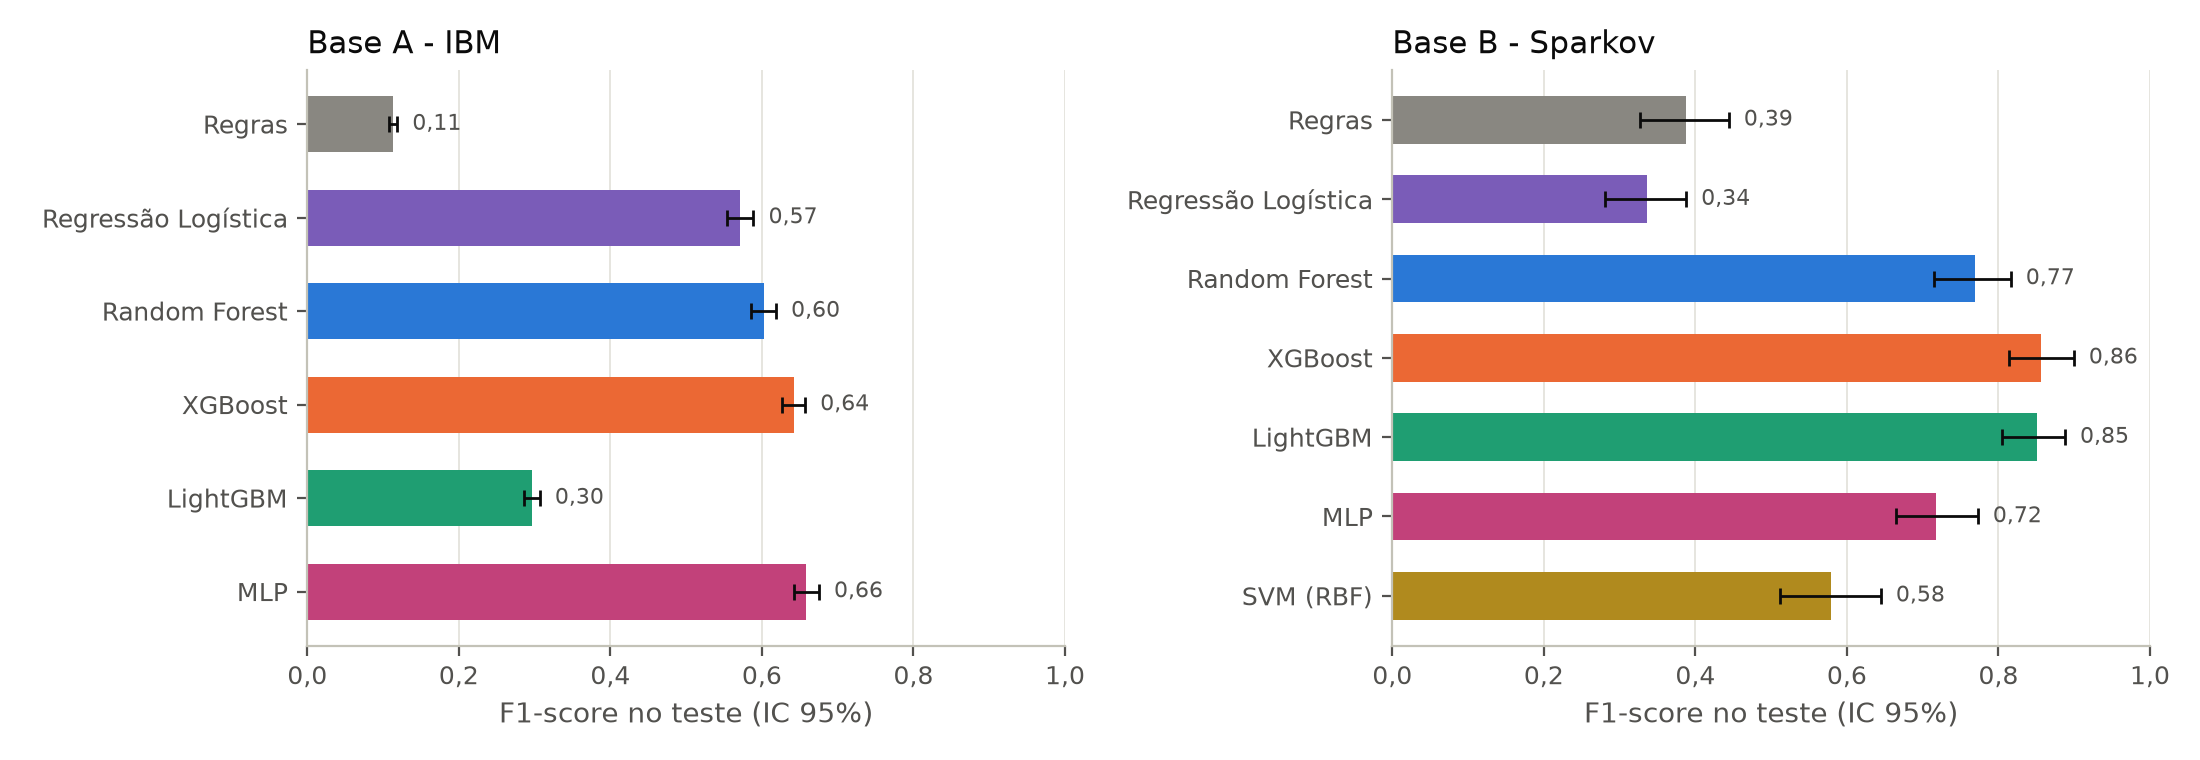

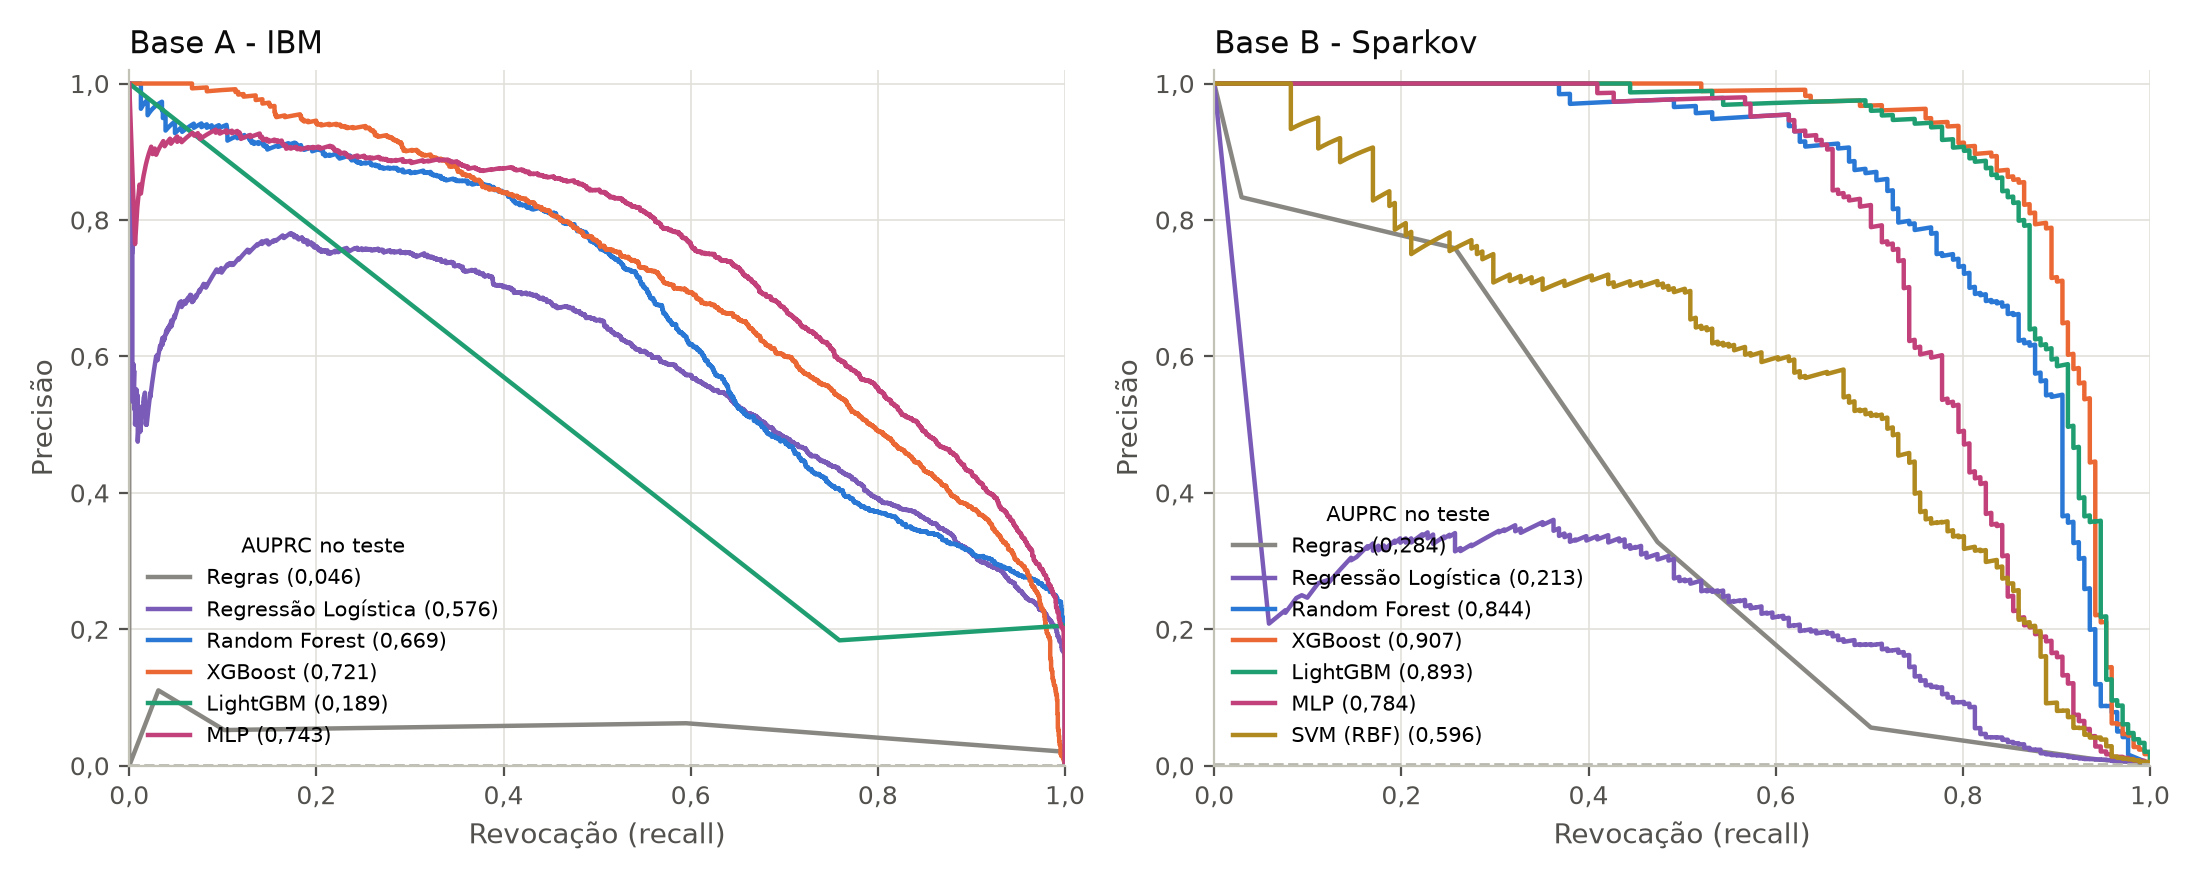

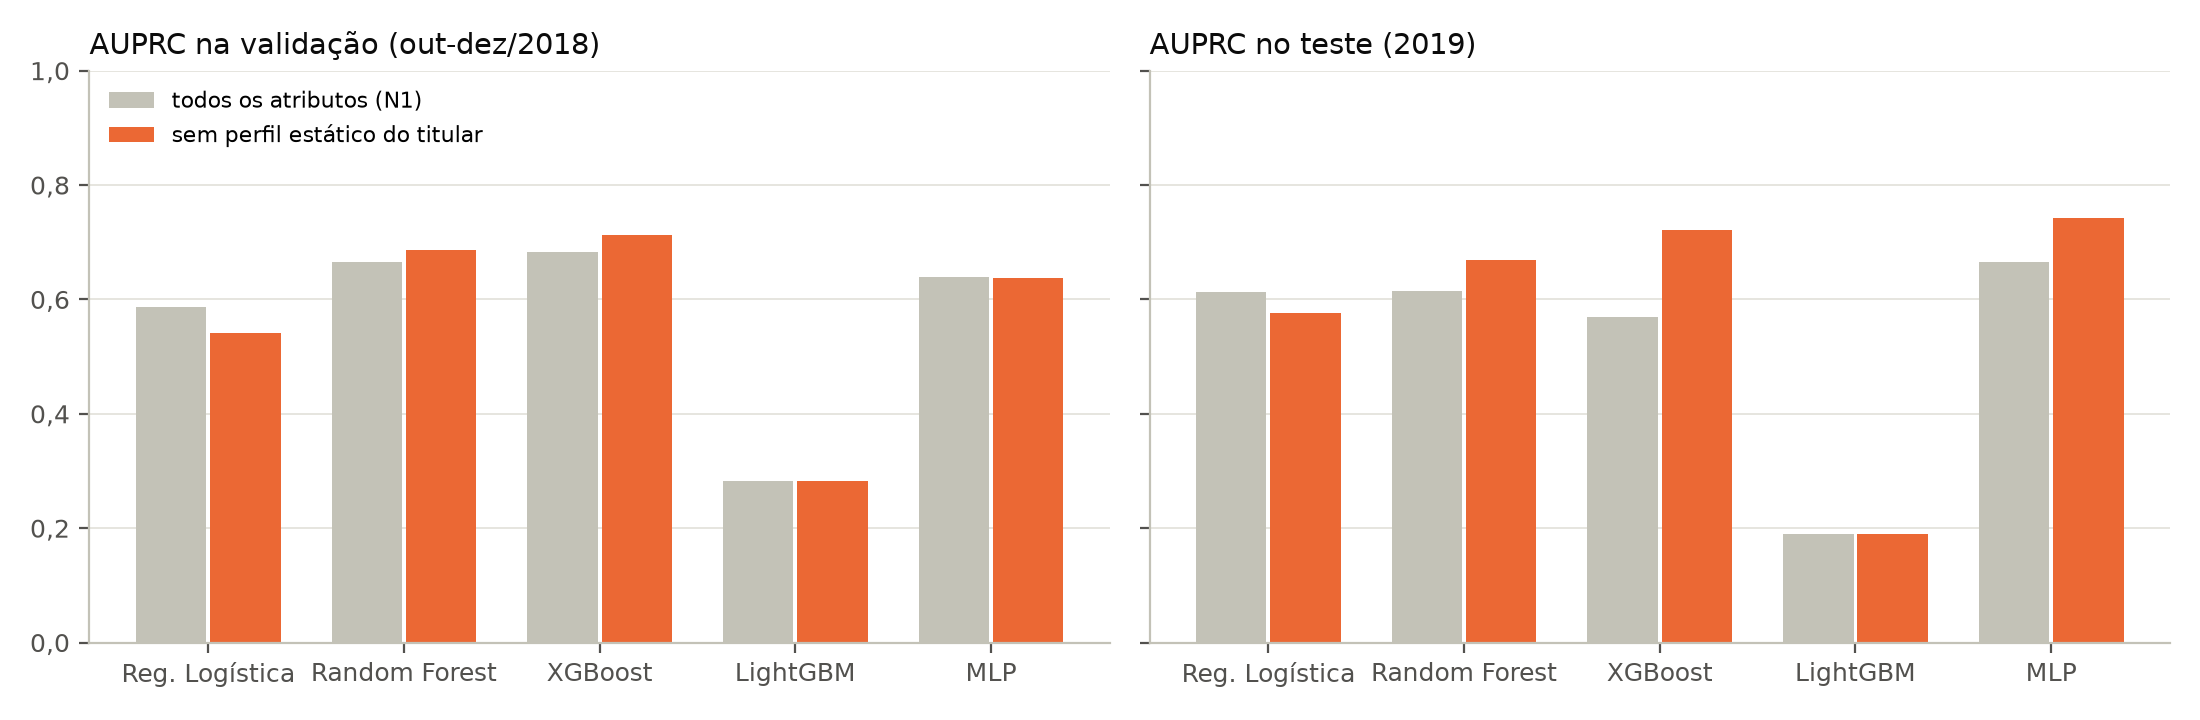

In [4]:
e1.figuras()
for f in ('fig_exp1_f1_ic.png', 'fig_exp1_curvas_pr.png', 'fig_exp1_perfil_estatico_A.png'):
    display(Image(FIG / f, width=1000))